## Constrained-area bypass dynamics (Flag 22)

### Dataset Overview
Constructed vessel movements around an independently supplied temporary maritime exclusion polygon in the west-Jutland offshore area.

The notebook exposes a primary table and a supporting table (`constrained_area.csv`).

Goal: Analyze how vessels adapt their movement patterns when navigating around a constrained maritime area.

Role: Maritime traffic analyst


Category: constrained-area bypass dynamics

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "constrained_area.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which paths do vessels use to avoid the constrained area?

#### Analysis action

Use the independent constrained-area polygon to identify the small set of recurring bypass geometries.

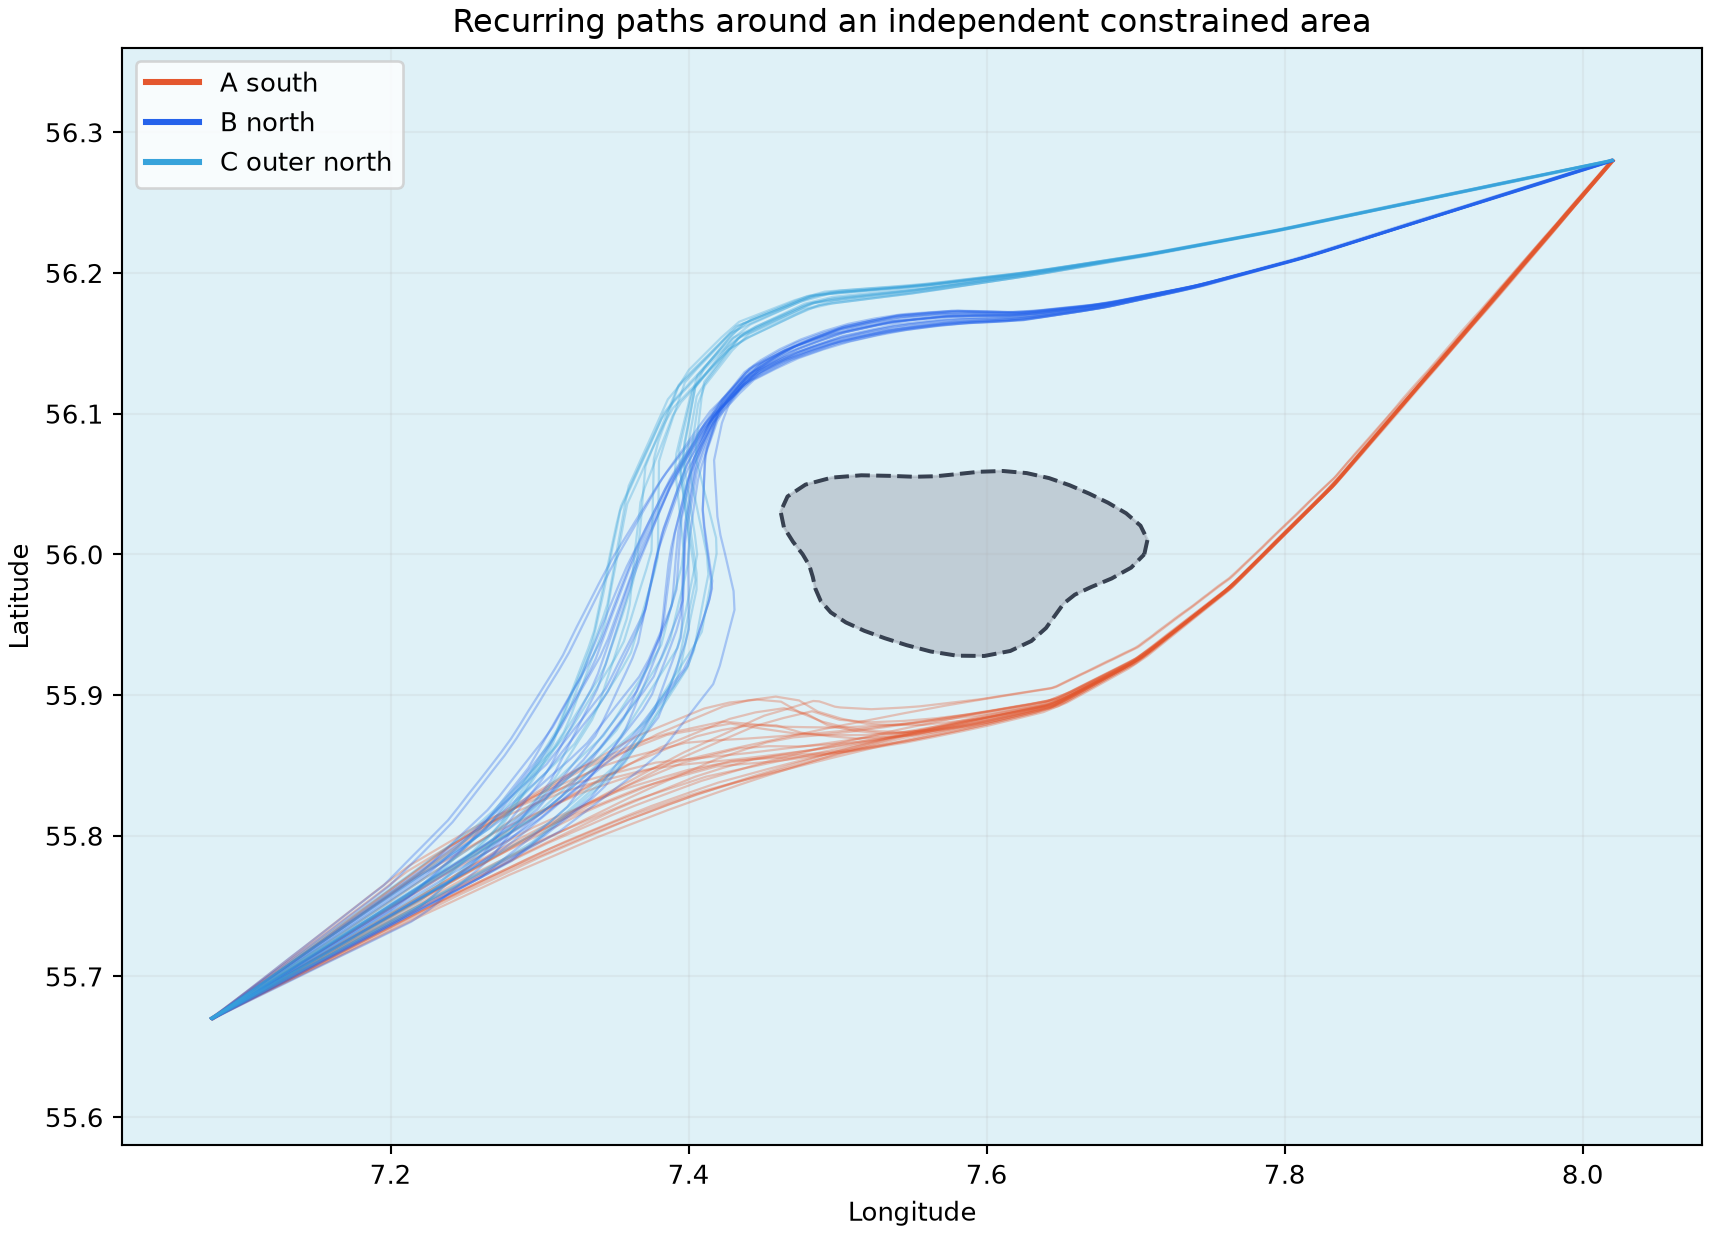

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); area=pd.read_csv(user_dataset_path); print(area[['area_id','restriction_type']].drop_duplicates()); print(df.groupby('bypass_path').trajectory_id.nunique())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/recurring_bypass_paths.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "recurring_bypass_paths",
  "insight": "Most vessels avoid the constrained area via a small number of recurring bypass paths.",
  "insight_value": {
    "bypass_path_counts": {
      "A_south": 25,
      "B_north": 22,
      "C_outer_north": 15
    }
  },
  "plot": {
    "plot_type": "path_colored_map",
    "title": "Recurring Bypass Paths",
    "file": "visualizations/recurring_bypass_paths.png",
    "description": "Use the independent constrained-area polygon to identify the small set of recurring bypass geometries."
  },
  "question": "Which paths do vessels use to avoid the constrained area?",
  "actionable_insight": "Use the independent constrained-area polygon to identify the small set of recurring bypass geometries.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); area=pd.read_csv(user_dataset_path); print(area[['area_id','restriction_type']].drop_duplicates()); print(df.groupby('bypass_path').trajectory_id.nunique())",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "constrained_area",
    "vessel_id"
  ]
}

### **Question 2**: How does traffic intensity affect speed adjustments near the area?

#### Analysis action

Compare short speed-adjustment counts near the independent boundary during high and quiet traffic periods.

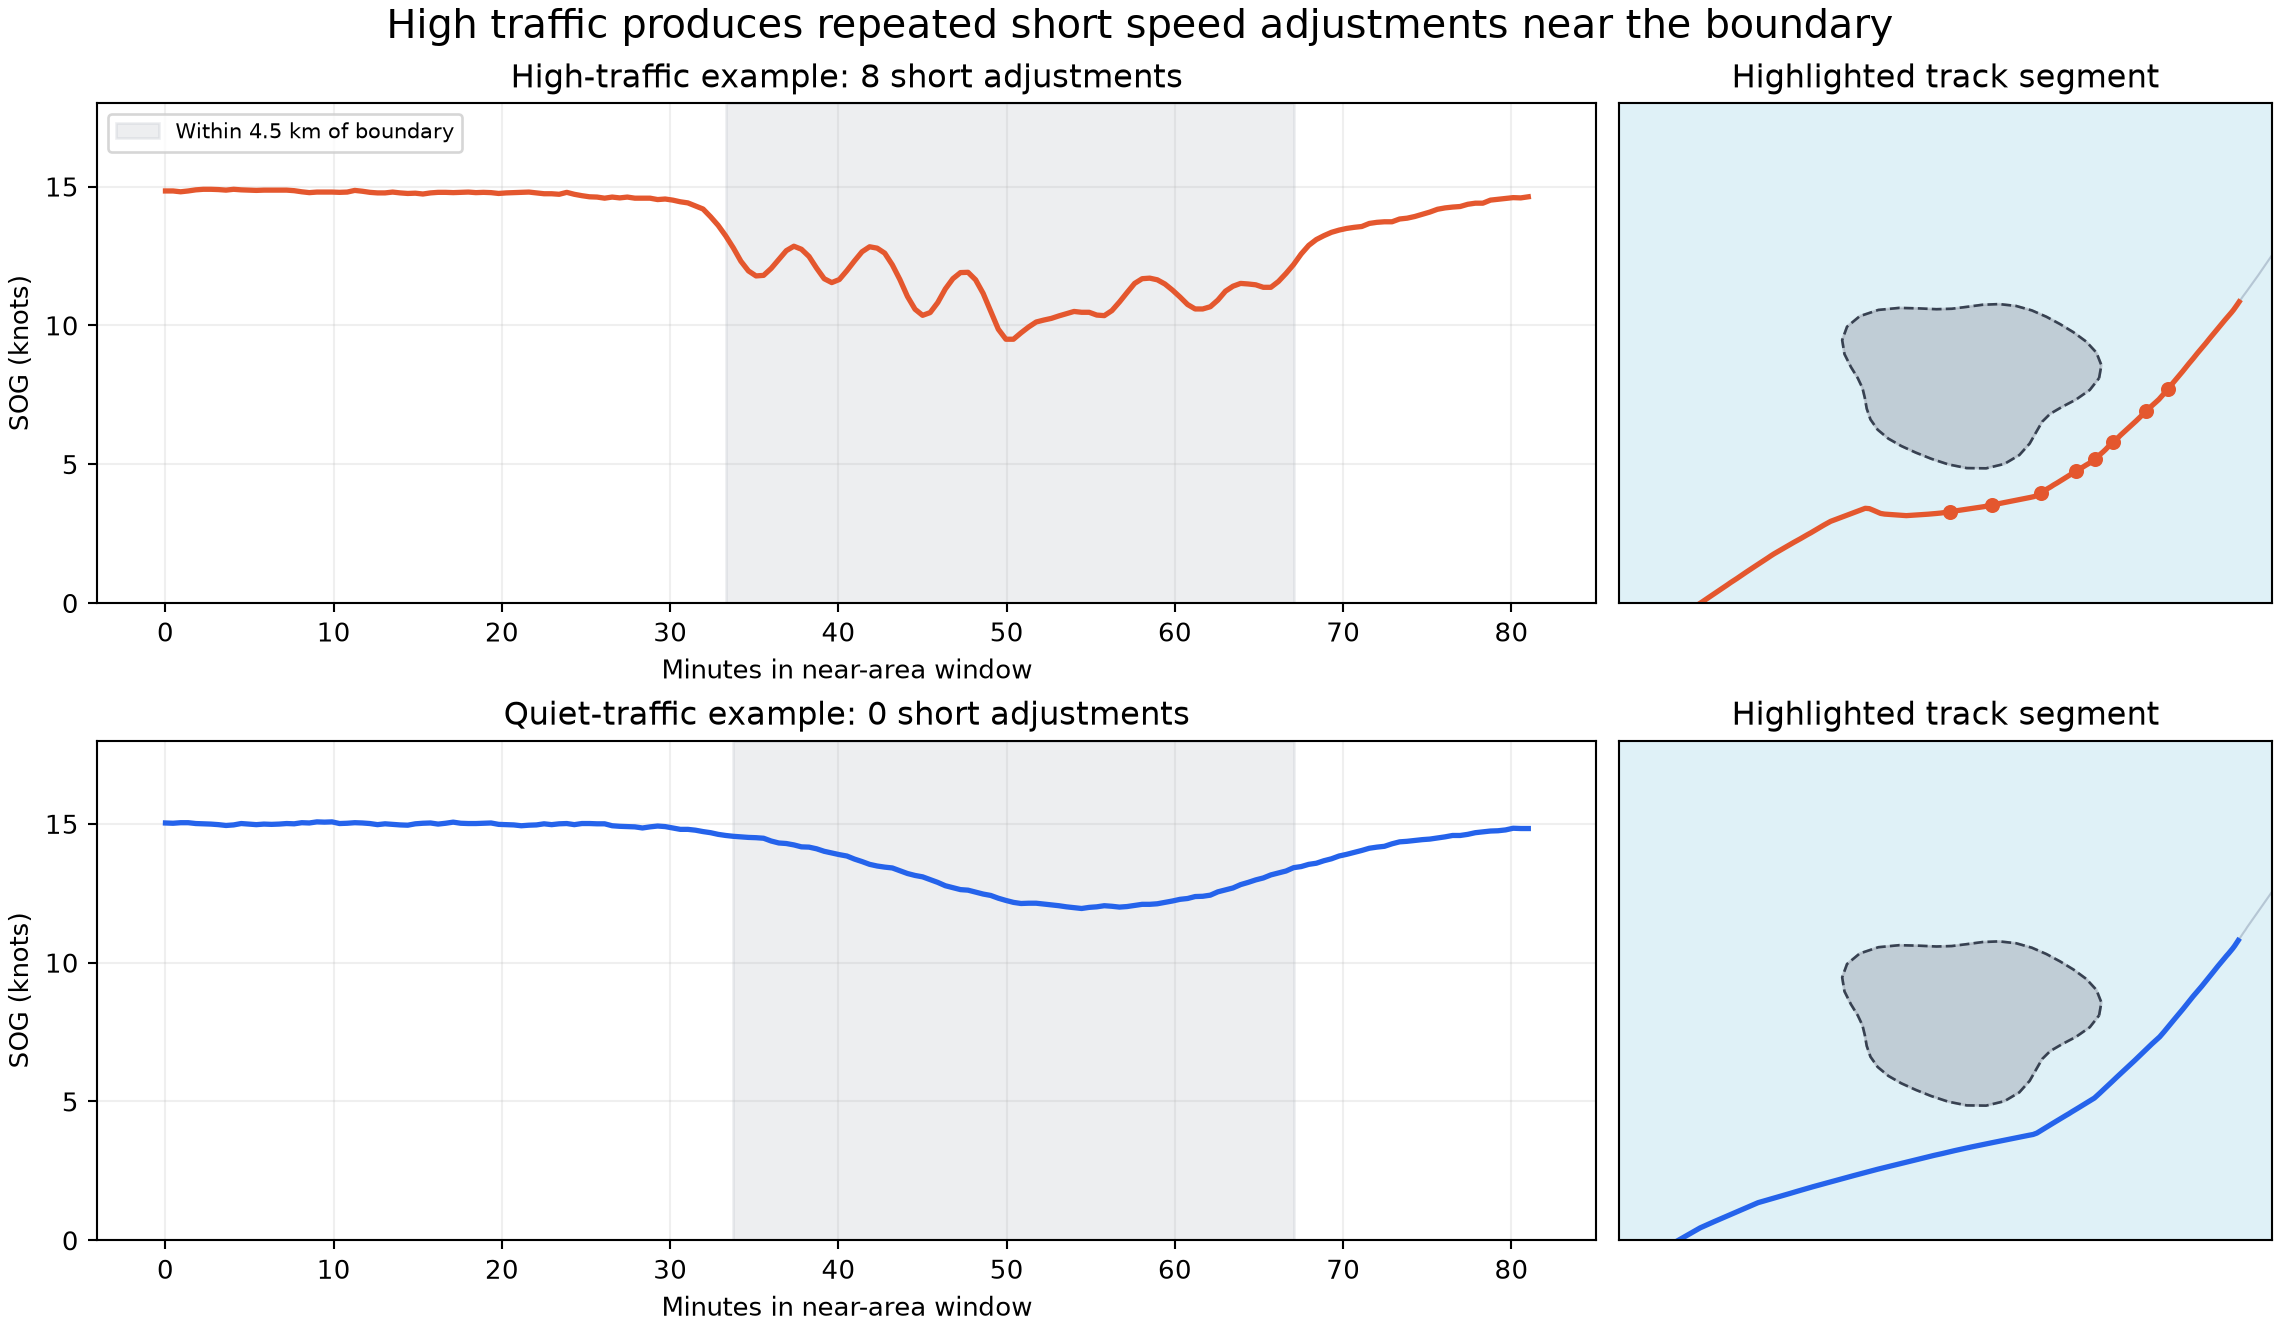

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby(['traffic_period','trajectory_id']).speed_adjustment_event.sum().groupby(level=0).describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/traffic_speed_adjustments.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "traffic_speed_adjustments",
  "insight": "Near the constrained area, high-traffic periods show more frequent short-term speed adjustments.",
  "insight_value": {
    "median_speed_adjustment_events": {
      "high": 8.0,
      "quiet": 1.0
    },
    "near_area_boundary_distance_km": 4.5
  },
  "plot": {
    "plot_type": "event_profile_and_distribution",
    "title": "Traffic-dependent Speed Adjustments",
    "file": "visualizations/traffic_speed_adjustments.png",
    "description": "Compare short speed-adjustment counts near the independent boundary during high and quiet traffic periods."
  },
  "question": "How does traffic intensity affect speed adjustments near the area?",
  "actionable_insight": "Compare short speed-adjustment counts near the independent boundary during high and quiet traffic periods.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby(['traffic_period','trajectory_id']).speed_adjustment_event.sum().groupby(level=0).describe())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "constrained_area",
    "point_speed",
    "vessel_id"
  ]
}

### **Question 3**: How is detour timing related to turning and speed reduction?

#### Analysis action

Define timing from continuous onset distance to the boundary, then compare turn sharpness and temporary speed reductions across the explicit threshold.

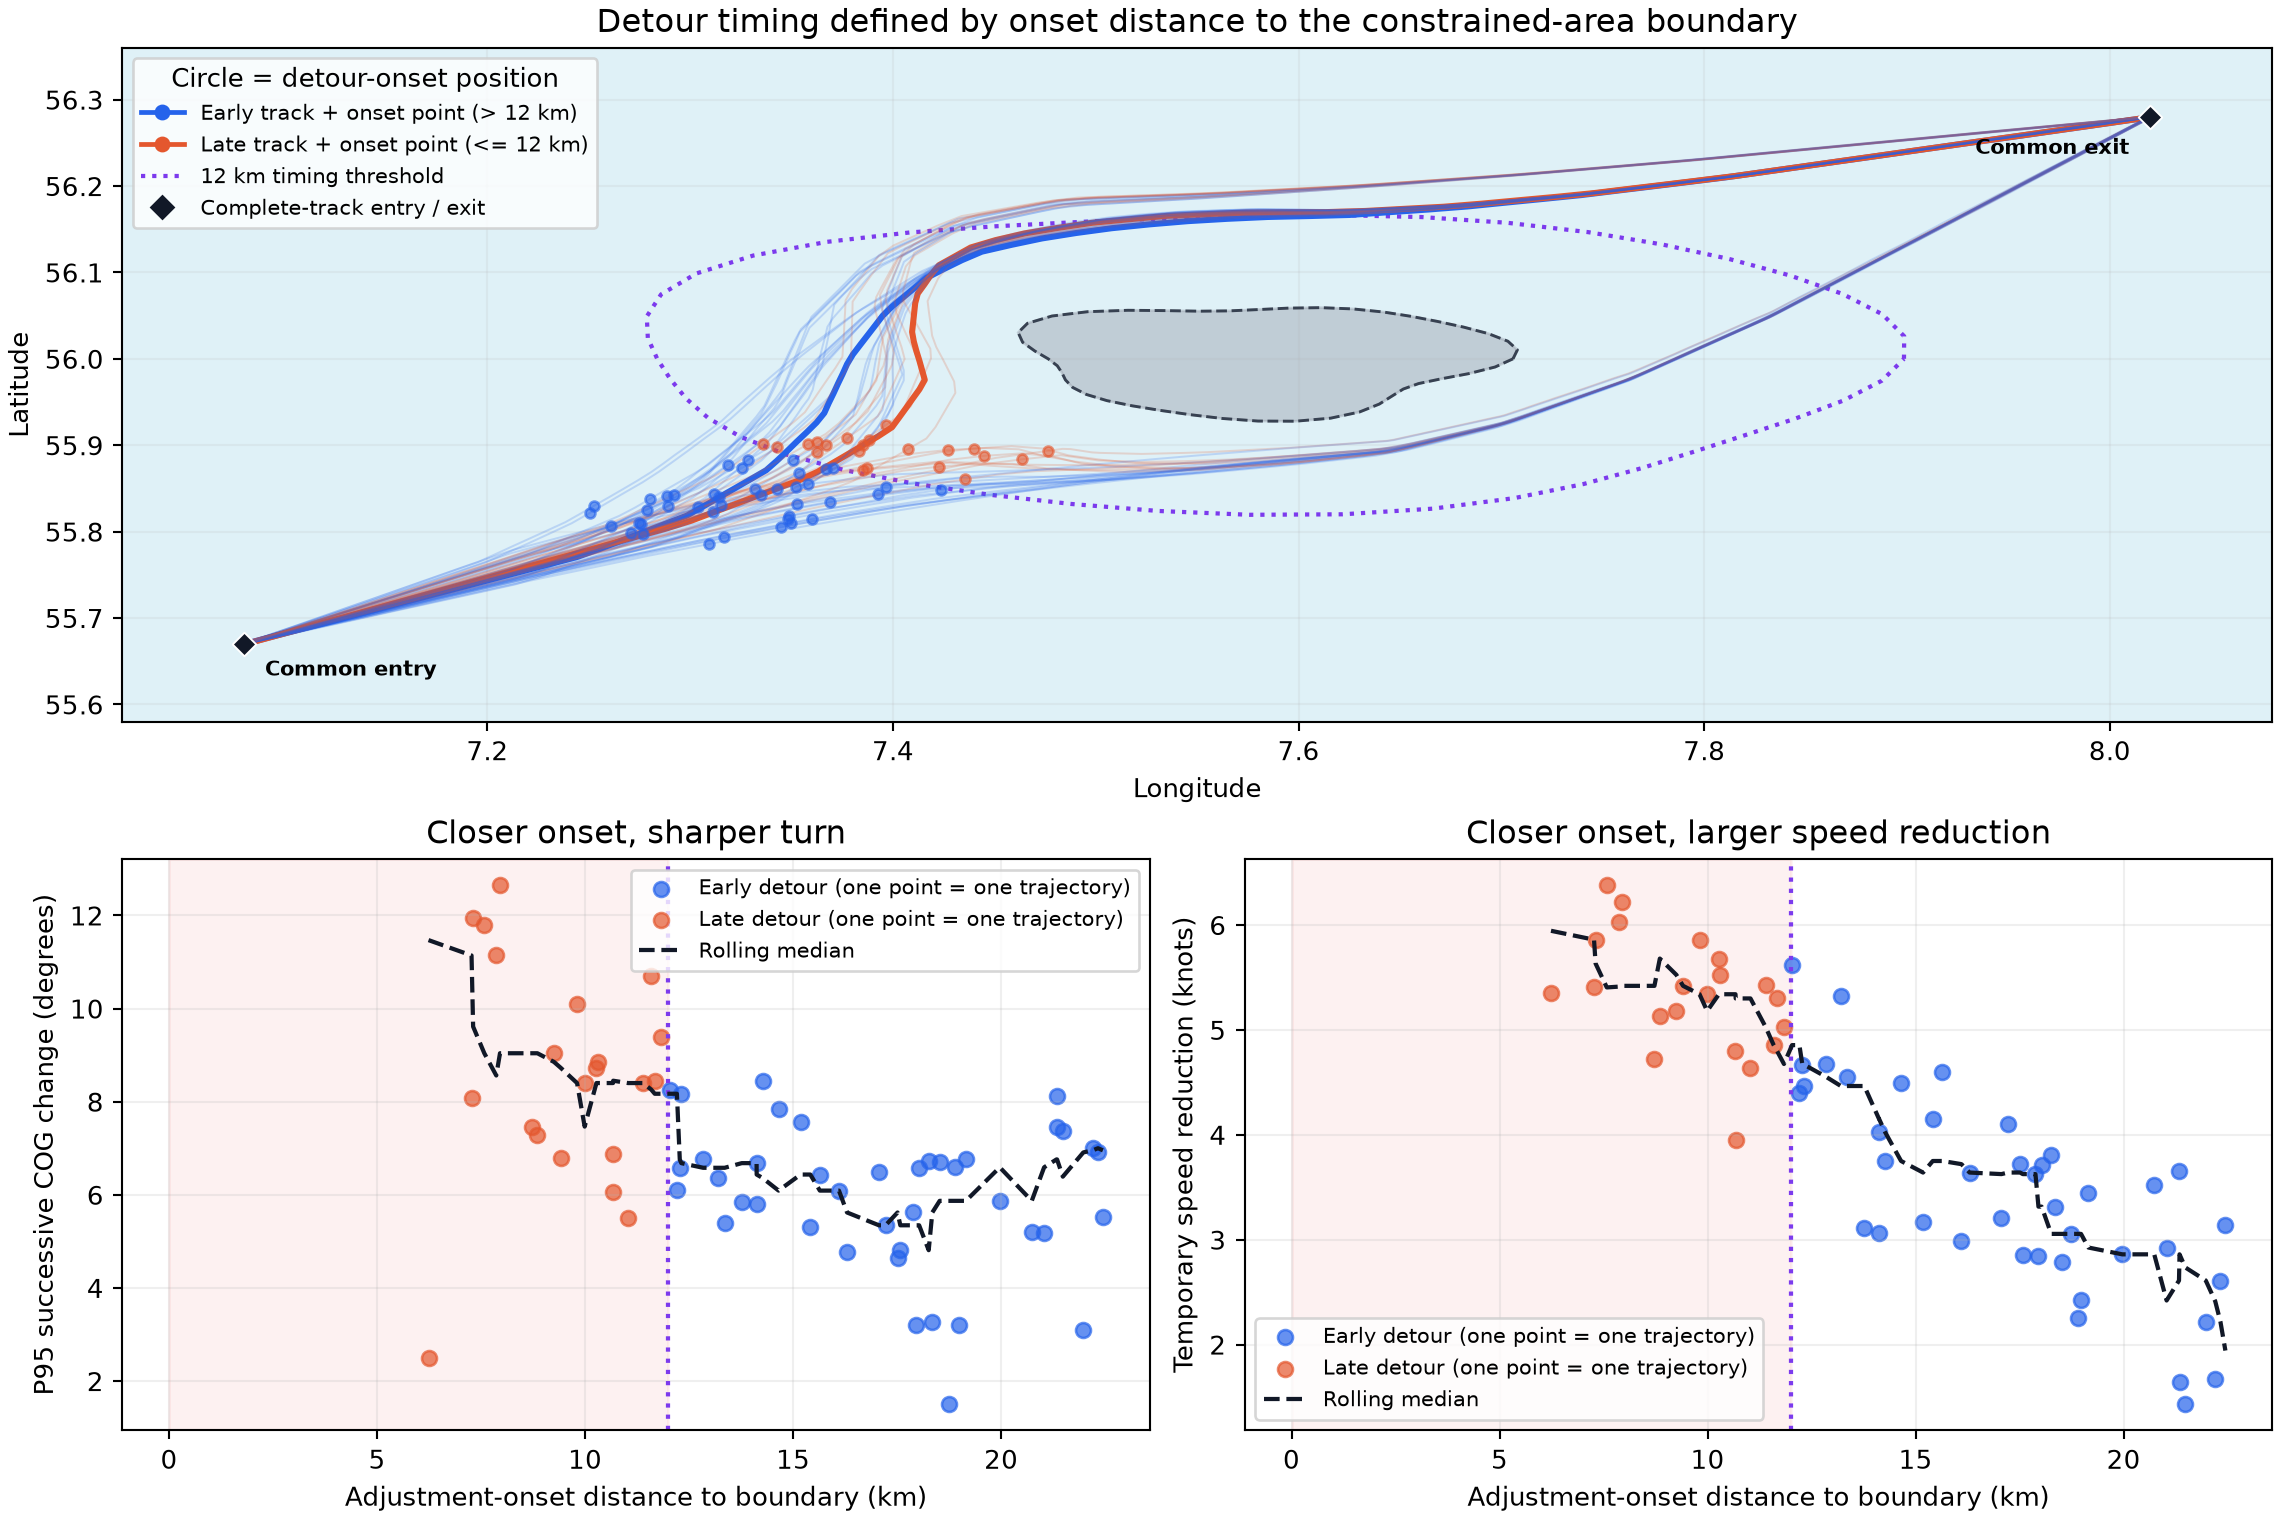

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); x=df.groupby('trajectory_id').first(); print(x.groupby('detour_timing').detour_onset_distance_km.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/detour_timing_effects.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "detour_timing_turn_speed",
  "insight": "Later detours are associated with sharper turns and larger temporary speed reductions.",
  "insight_value": {
    "detour_timing_rule": {
      "threshold_km": 12.0,
      "early": "> 12 km from boundary",
      "late": "<= 12 km from boundary"
    },
    "median_onset_distance_to_boundary_km": {
      "early": 17.58,
      "late": 9.81
    },
    "median_p95_turn_deg": {
      "early": 6.36,
      "late": 8.45
    },
    "median_speed_reduction_knots": {
      "early": 3.44,
      "late": 5.35
    },
    "onset_distance_spearman": {
      "turn_sharpness": -0.519,
      "speed_reduction": -0.889
    }
  },
  "plot": {
    "plot_type": "continuous_distance_and_threshold",
    "title": "Early and Late Detour Effects",
    "file": "visualizations/detour_timing_effects.png",
    "description": "Define timing from continuous onset distance to the boundary, then compare turn sharpness and temporary speed reductions across the explicit threshold."
  },
  "question": "How is detour timing related to turning and speed reduction?",
  "actionable_insight": "Define timing from continuous onset distance to the boundary, then compare turn sharpness and temporary speed reductions across the explicit threshold.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); x=df.groupby('trajectory_id').first(); print(x.groupby('detour_timing').detour_onset_distance_km.describe())",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "constrained_area",
    "course_over_ground",
    "point_speed",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 22)

Most vessels avoid the constrained area via a small number of recurring bypass paths. Near the constrained area, high-traffic periods show more frequent short-term speed adjustments. Later detours are associated with sharper turns and larger temporary speed reductions.